<a href="https://colab.research.google.com/github/Deangr-econ/torch-volatility-engine/blob/main/HAR_Markov_Switching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from google.colab import userdata
import torch
import time
import numba
from scipy.optimize import minimize
# from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

# 1. Load data
data_futures = pd.read_csv(userdata.get('Future_data'))

# 2. Filter symbol & set date index directly
df = (
    data_futures.query("symbol == 'NG'")
    .set_index('date')[['rv5', 'rsp5', 'rsn5']]
)

# 3. Feature engineering (HAR daily, weekly, monthly features)
data = df[['rsp5', 'rsn5', 'rv5']].copy()

for feature in ['rsp5', 'rsn5', 'rv5']:
    data[f'{feature}_w'] = data[feature].rolling(5).mean()   # Added ()
    data[f'{feature}_m'] = data[feature].rolling(22).mean()  # Added ()

# Lag all features by 1 day to prevent look-ahead bias
data = data.shift(1)

# Add target column back and drop initial rolling NaNs
data['rv5_p'] = df['rv5']
data = data.dropna()

# 4. Define target & predictors dynamically
all_features = [col for col in data.columns if col != 'rv5_p']
y = data['rv5_p']
X = data[all_features].assign(const=1.0)[['const'] + all_features]

# 5. Solve for OLS parameters & predict
beta = np.linalg.solve(X.T @ X, X.T @ y)
pred = X.values @ beta

# 6. Evaluation metrics
e = y - pred
rmsfe = np.sqrt((e**2).mean())

ss_res = np.sum(e**2)
ss_tot = np.sum((y - y.mean())**2)
r_squared = 1 - (ss_res / ss_tot)

print(f"RMSFE: {rmsfe:.6f}")
print(f"R²:    {r_squared:.4f}")

RMSFE: 0.001653
R²:    0.1436


In [2]:
data

,rsp5,rsn5,rv5,rsp5_w,rsp5_m,rsn5_w,rsn5_m,rv5_w,rv5_m,rv5_p
date,,,,,,,,,,
2009-10-28,0.000664,0.000437,0.001101,0.000713,0.003782,0.000838,0.000873,0.001551,0.004656,0.030706
2009-10-29,0.029650,0.001056,0.030706,0.006436,0.002141,0.000806,0.000857,0.007243,0.002998,0.001235
2009-10-30,0.000625,0.000610,0.001235,0.006380,0.002108,0.000740,0.000842,0.007120,0.002950,0.001344
2009-11-02,0.000568,0.000776,0.001344,0.006410,0.002105,0.000763,0.000847,0.007173,0.002952,0.001318
2009-11-03,0.000399,0.000919,0.001318,0.006381,0.002095,0.000760,0.000826,0.007141,0.002921,0.000886
...,...,...,...,...,...,...,...,...,...,...
2026-09-24,0.002027,0.000380,0.002407,0.000617,0.000345,0.000246,0.000261,0.000863,0.000606,0.001948
2026-09-25,0.001128,0.000820,0.001948,0.000800,0.000384,0.000365,0.000284,0.001165,0.000668,0.000915
2026-09-28,0.000440,0.000474,0.000915,0.000833,0.000393,0.000422,0.000298,0.001256,0.000691,0.000831


In [3]:
def build_tensor(df, target_col='rv5', train_pct=0.80):
    """
    Packs expanding window feature matrices and target vectors into 3D tensors.

    Returns:
        X_3d: Tensor of shape (test_size, max_window_len, K)
        y_3d: Tensor of shape (test_size, max_window_len)
        X_test: Out-of-sample feature vectors of shape (test_size, 1, K)
        y_test: Actual out-of-sample target values of shape (test_size,)
    """
    # 1. Separate features and target
    feature_cols = [col for col in df.columns if col != target_col]

    # Extract values and create constant term for X
    y_tensor = torch.tensor(df[target_col].values, dtype=torch.float64)

    X_df = df[feature_cols].assign(const=1.0)[['const'] + feature_cols]
    X_tensor = torch.tensor(X_df.values, dtype=torch.float64)

    # 2. Calculate dimensions
    N, K = X_tensor.shape
    train_split = int(train_pct * N)
    test_size = N - train_split
    max_window_len = N - 1  # Maximum row length across all expanding windows

    # 3. Initialize 3D containers (padded with zeros)
    X_3d = torch.zeros((test_size, max_window_len, K), dtype=torch.float64)
    y_3d = torch.zeros((test_size, max_window_len), dtype=torch.float64)

    # 4. Fill expanding window slices (LEGO blocks)
    for i in range(test_size):
        cur_len = train_split + i
        X_3d[i, :cur_len, :] = X_tensor[:cur_len, :]
        y_3d[i, :cur_len] = y_tensor[:cur_len]

    X_test = X_tensor[train_split:N, :].unsqueeze(1)
    y_test = y_tensor[train_split:N]

    return X_3d, y_3d, X_test, y_test


def solve_expanding_ols(X_3d, y_3d, X_test):
    """
    Solves M expanding-window OLS regressions simultaneously and generates
    1-step-ahead out-of-sample forecasts using PyTorch batched tensor ops.

    Parameters:
    -----------
    X_3d   : Tensor of shape (M, max_window_len, K)
    y_3d   : Tensor of shape (M, max_window_len)
    X_test : Tensor of shape (M, 1, K)

    Returns:
    --------
    y_pred : Tensor of shape (M,) containing 1-step-ahead forecasts
    betas  : Tensor of shape (M, K) containing estimated coefficients for all windows
    """
    # 1. Reshape y_3d to (M, max_window_len, 1) for matrix multiplication
    y_3d_col = y_3d.unsqueeze(-1)

    # 2. Compute X^T * X for all M windows simultaneously -> Shape: (M, K, K)
    # transpose(1, 2) flips (max_window_len, K) to (K, max_window_len)
    XtX = torch.bmm(X_3d.transpose(1, 2), X_3d)

    # 3. Compute X^T * y for all M windows simultaneously -> Shape: (M, K, 1)
    Xty = torch.bmm(X_3d.transpose(1, 2), y_3d_col)

    # 4. Solve XtX * beta = Xty for beta across all M models -> Shape: (M, K, 1)
    betas_col = torch.linalg.solve(XtX, Xty)

    # 5. Generate 1-step-ahead predictions: X_test * beta -> Shape: (M, 1, 1)
    y_pred_3d = torch.bmm(X_test, betas_col)

    # 6. Flatten dimensions back to clean 1D and 2D arrays
    y_pred = y_pred_3d.squeeze()       # Shape: (M,)
    betas = betas_col.squeeze(-1)       # Shape: (M, K)

    return y_pred, betas


def rmsfe(y_true, y_pred):
    return torch.sqrt(torch.mean((y_true - y_pred) ** 2)).item()


def FSP(df, target_col='rv5', train_pct=0.80):
    X_3d, y_3d, X_test, y_test = build_tensor(df, target_col, train_pct)
    y_pred, betas = solve_expanding_ols(X_3d, y_3d, X_test)
    rmsfe_val = rmsfe(y_test, y_pred)

    return rmsfe_val, y_pred, betas, y_test

def get_forecast_metrics(y_true, y_pred, is_log=False):
    """
    Computes core out-of-sample volatility forecasting performance metrics.

    Parameters:
    -----------
    y_true : array-like
        Actual volatility series.
    y_pred : array-like
        Forecasted volatility series.
    is_log : bool, optional
        If True, exponentiates both arrays before calculating metrics to evaluate on original scale.

    Returns:
    --------
    dict
        A dictionary containing RMSE, MAE, and QLIKE values.
    """
    # Convert to numpy arrays if necessary
    y_t = np.array(y_true)
    y_p = np.array(y_pred)

    if is_log:
        y_t = np.exp(y_t)
        y_p = np.exp(y_p)

    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mae = np.mean(np.abs(y_t - y_p))

    # QLIKE loss: standard asymmetric loss function for volatility forecasts
    # Handles dividing by zero with safety checks
    with np.errstate(divide='ignore', invalid='ignore'):
        qlike = np.mean(y_t / y_p - np.log(y_t / y_p) - 1.0) if np.all(y_p > 0) else np.nan

    return {
        'RMSE': float(rmse),
        'MAE': float(mae),
        'QLIKE': float(qlike)
    }

# Example of usage:
# metrics = get_forecast_metrics(y_test_base_np, pred_base_ols_np)
# print(metrics)

In [4]:
# 1. Run both models and retrieve out-of-sample forecasts and targets
log_rmsfe, log_pred_log_scale, _, y_test_log_scale = FSP(df=np.log(data), target_col='rv5', train_pct=0.80)
level_rmsfe, level_pred, _, y_test_level = FSP(df=data, target_col='rv5', train_pct=0.80)

# 2. Exponentiate log model predictions to bring them back to the original scale
# Note: exp(y_pred) brings it back to the original unit scale
log_pred_original_scale = torch.exp(log_pred_log_scale)
actual_level = torch.exp(y_test_log_scale) # matches y_test_level

# 3. Calculate comparable RMSFE on the original scale
comparable_log_rmsfe = torch.sqrt(torch.mean((actual_level - log_pred_original_scale) ** 2)).item()

print("=== Performance Comparison on Original Scale ===")
print(f"Level Model RMSFE:        {level_rmsfe:.6f}")
print(f"Log Model (scaled) RMSFE: {comparable_log_rmsfe:.6f}")

=== Performance Comparison on Original Scale ===
Level Model RMSFE:        0.000000
Log Model (scaled) RMSFE: 0.000981


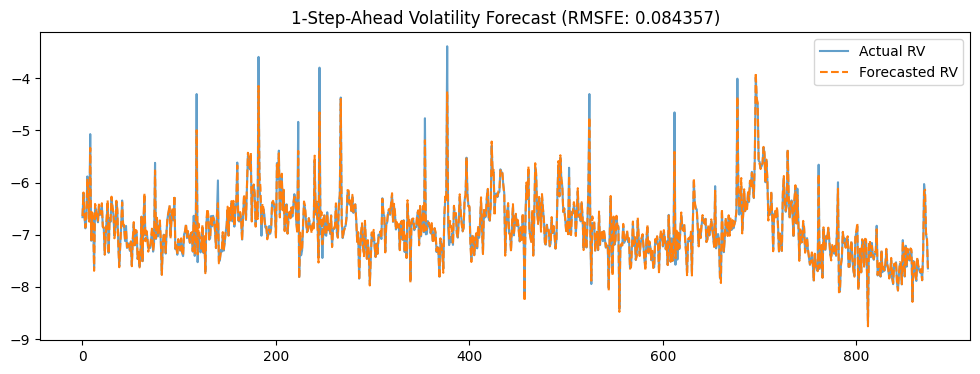

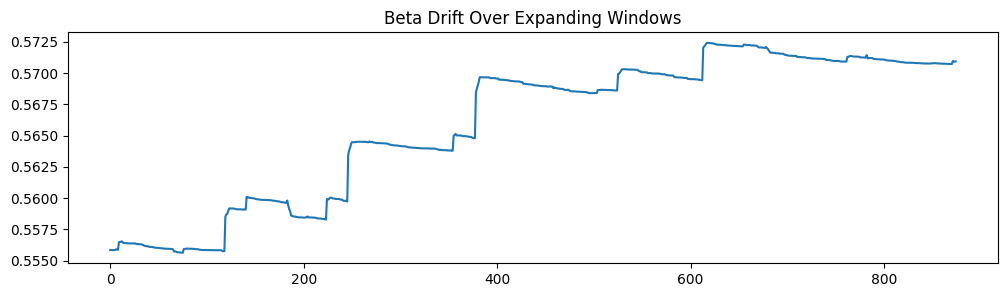

In [5]:
# Run the full pipeline
rmsfe_val, y_pred, betas, y_test = FSP(np.log(data))

# 1. Plot actual vs predicted volatility
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(y_test.numpy(), label='Actual RV', alpha=0.7)
plt.plot(y_pred.numpy(), label='Forecasted RV', linestyle='--')
plt.title(f'1-Step-Ahead Volatility Forecast (RMSFE: {rmsfe_val:.6f})')
plt.legend()
plt.show()

# 2. Plot parameter drift over time for a feature (e.g., daily negative semivariance)
plt.figure(figsize=(12, 3))
plt.plot(betas[:, 1].numpy())  # Index 1 = first feature after constant
plt.title('Beta Drift Over Expanding Windows')
plt.show()

In [6]:
# ---------------------------------------------------------
# 1. Prepare Target (y) and Exogenous Regressors (exog)
# ---------------------------------------------------------
# Recommendation: Use log(RV) to stabilize variance and ensure
# symmetric Gaussian error terms across regimes.
use_log = True
work_df = np.log(data) if use_log else data.copy()

# Target variable (daily RV)
y = work_df['rv5']

# Exogenous features: daily, weekly, and monthly positive & negative semivariances
feature_cols = ['rsp5', 'rsn5', 'rsp5_w', 'rsn5_w', 'rsp5_m', 'rsn5_m']
exog = work_df[feature_cols]

In [7]:
# # ---------------------------------------------------------
# # 2. Define the 2-Regime Markov Switching Model
# # ---------------------------------------------------------
# # - k_regimes=2: Low volatility (Calm) vs High volatility (Crisis)
# # - trend='c': Include an intercept
# # - switching_trend=True: Allow the intercept to switch between regimes
# # - switching_exog=True: Allow all beta coefficients to switch
# # - switching_variance=True: Allow residual variance (sigma^2) to switch
# ms_har_model = MarkovRegression(
#     endog=y,
#     k_regimes=2,
#     trend='c',
#     exog=exog,
#     switching_trend=True,
#     switching_exog=True,
#     switching_variance=True
# )

# # ---------------------------------------------------------
# # 3. Fit via Maximum Likelihood Estimation (MLE)
# # ---------------------------------------------------------
# # search_reps: Runs multiple initial parameter guesses to prevent getting stuck
# # in poor local likelihood optima.
# ms_res = ms_har_model.fit(search_reps=25)

# # Print detailed summary (betas, transition probabilities, expected durations)
# print(ms_res.summary())

In [8]:
# # ---------------------------------------------------------
# # 1. The Fast Compiled Hamilton Log-Likelihood Kernel
# # ---------------------------------------------------------
# @numba.njit(fastmath=True)
# def fast_hamilton_ll(mu0, mu1, y, s0, s1, p00, p11):
#     T = len(y)
#     p01 = 1.0 - p00
#     p10 = 1.0 - p11
#     inv_s0 = 1.0 / (s0 * 2.506628274631)
#     inv_s1 = 1.0 / (s1 * 2.506628274631)

#     # Ergodic steady-state prior at t = 0
#     d = p01 + p10
#     xi0 = p10 / d if d > 1e-12 else 0.5
#     xi1 = 1.0 - xi0
#     ll = 0.0

#     for t in range(T):
#         # 1. State prediction (Markov projection)
#         pr0 = p00 * xi0 + p10 * xi1
#         pr1 = p01 * xi0 + p11 * xi1

#         # 2. Gaussian conditional densities
#         e0 = (y[t] - mu0[t]) / s0
#         e1 = (y[t] - mu1[t]) / s1
#         eta0 = inv_s0 * np.exp(-0.5 * e0 * e0)
#         eta1 = inv_s1 * np.exp(-0.5 * e1 * e1)

#         # 3. Mixture density & accumulation
#         f = pr0 * eta0 + pr1 * eta1
#         if f < 1e-300:
#             f = 1e-300
#         ll += np.log(f)

#         # 4. Posterior Bayes update
#         xi0 = (pr0 * eta0) / f
#         xi1 = (pr1 * eta1) / f

#     return ll, xi0, xi1


# # ---------------------------------------------------------
# # 2. The SciPy Objective Wrapper
# # ---------------------------------------------------------
# def objective_hamilton(theta, X, y, K):
#     """
#     Unpacks parameter vector theta, evaluates conditional mean vectors mu0 and mu1,
#     and returns negative log-likelihood for SciPy minimization.

#     theta layout:
#       theta[0 : K]       -> beta_0
#       theta[K : 2*K]     -> beta_1
#       theta[2*K]         -> sigma_0
#       theta[2*K + 1]     -> sigma_1
#       theta[2*K + 2]     -> p00
#       theta[2*K + 3]     -> p11
#     """
#     # 1. Unpack parameters
#     beta0 = theta[:K]
#     beta1 = theta[K:2*K]
#     s0    = theta[2*K]
#     s1    = theta[2*K + 1]
#     p00   = theta[2*K + 2]
#     p11   = theta[2*K + 3]

#     # 2. Safety bounds check (in case optimizer takes an out-of-bounds finite step)
#     if s0 <= 1e-6 or s1 <= 1e-6 or p00 <= 1e-6 or p00 >= 1.0 - 1e-6 or p11 <= 1e-6 or p11 >= 1.0 - 1e-6:
#         return 1e12

#     # 3. Vector matrix-vector dot products (BLAS level-2: instantaneous)
#     # mu0 and mu1 are 1D vectors of shape (T,)
#     mu0 = X @ beta0
#     mu1 = X @ beta1

#     # 4. Call compiled Numba kernel
#     ll, _, _ = fast_hamilton_ll(mu0, mu1, y, s0, s1, p00, p11)

#     # 5. Return negative log-likelihood
#     if np.isnan(ll) or np.isinf(ll):
#         return 1e12

#     return -ll

In [9]:
# X_window = np.ascontiguousarray(exog.values, dtype=np.float64)
# y_window = np.ascontiguousarray(y.values, dtype=np.float64)

# # Assuming X_window has shape (T, K) and y_window has shape (T,)
# T_win, K = X_window.shape

# # 1. Quick OLS baseline to get sensible initial guesses
# beta_ols = np.linalg.lstsq(X_window, y_window, rcond=None)[0]
# resids = y_window - X_window @ beta_ols
# s_ols = np.std(resids)

# # 2. Construct initial parameter guess x0
# # Regime 0 = Low volatility, Regime 1 = High volatility
# init_beta0 = beta_ols * 0.95
# init_beta1 = beta_ols * 1.05
# init_s0 = s_ols * 0.75
# init_s1 = s_ols * 1.50
# init_p00 = 0.95
# init_p11 = 0.85

# x0 = np.concatenate([
#     init_beta0,
#     init_beta1,
#     [init_s0, init_s1, init_p00, init_p11]
# ])

# # 3. Define parameter bounds for L-BFGS-B
# bounds = (
#     [(None, None)] * K +            # beta0
#     [(None, None)] * K +            # beta1
#     [(1e-4, 50.0), (1e-4, 50.0)] +  # s0, s1 (strictly positive)
#     [(1e-4, 0.9999), (1e-4, 0.9999)]# p00, p11 (strictly in (0, 1))
# )

# # 4. Minimize
# res = minimize(
#     fun=objective_hamilton,
#     x0=x0,
#     args=(X_window, y_window, K),
#     method='L-BFGS-B',
#     bounds=bounds,
#     options={'maxiter': 150, 'ftol': 1e-7, 'gtol': 1e-5}
# )

# print(f"Convergence: {res.success}")
# print(f"Iterations:  {res.nit}")
# print(f"Final -LL:   {res.fun:.4f}")

In [10]:
# # Unpack the fitted parameter vector
# beta0_fit = res.x[:K]
# beta1_fit = res.x[K:2*K]
# s0_fit    = res.x[2*K]
# s1_fit    = res.x[2*K + 1]
# p00_fit   = res.x[2*K + 2]
# p11_fit   = res.x[2*K + 3]

# # Expected duration in days: 1 / (1 - p_ii)
# dur0 = 1.0 / (1.0 - p00_fit)
# dur1 = 1.0 / (1.0 - p11_fit)

# print("=== REGIME 0 (Low Volatility) ===")
# print(f"Residual Std (s0): {s0_fit:.5f}")
# print(f"Persistence (p00): {p00_fit:.4f}  ->  Expected Duration: {dur0:.1f} days")
# print(f"Beta0: {np.round(beta0_fit, 4)}\n")

# print("=== REGIME 1 (High Volatility) ===")
# print(f"Residual Std (s1): {s1_fit:.5f}")
# print(f"Persistence (p11): {p11_fit:.4f}  ->  Expected Duration: {dur1:.1f} days")
# print(f"Beta1: {np.round(beta1_fit, 4)}")

In [11]:
# # =====================================================================
# # REPLACEMENT CODE FOR CELL [24]
# # Fixes: IndexError on line 18 by using the last in-sample row (-1)
# # =====================================================================

# # 1. Pre-calculate conditional means using the optimal betas
# mu0_opt = X_window @ beta0_fit
# mu1_opt = X_window @ beta1_fit

# # 2. Run the Numba filter one final time to extract terminal filtered probabilities
# _, xi0_T, xi1_T = fast_hamilton_ll(
#     mu0_opt, mu1_opt, y_window,
#     s0_fit, s1_fit, p00_fit, p11_fit
# )

# # 3. Project state probabilities 1 step forward into the future (P.T @ xi_T)
# xi0_next = p00_fit * xi0_T + (1.0 - p11_fit) * xi1_T
# xi1_next = (1.0 - p00_fit) * xi0_T + p11_fit * xi1_T

# # 4. Predict 1-step ahead realized volatility
# # Use the last row of X_window (-1) as the forecast origin vector
# x_tomorrow = X_window[-1, :].astype(np.float64)

# mu0_pred = np.dot(x_tomorrow, beta0_fit)
# mu1_pred = np.dot(x_tomorrow, beta1_fit)

# # Final 1-step ahead expectation
# y_hat_next = xi0_next * mu0_pred + xi1_next * mu1_pred

# print(f"Terminal State Belief:  P(Regime 0) = {xi0_T:.4f} | P(Regime 1) = {xi1_T:.4f}")
# print(f"Projected State (t+1):  P(Regime 0) = {xi0_next:.4f} | P(Regime 1) = {xi1_next:.4f}")
# print(f"1-Step Ahead Forecast:  {y_hat_next:.5f}")

In [12]:
# import numpy as np
# from scipy.optimize import minimize
# import time

# # ---------------------------------------------------------------------
# # SETUP: Adjust these names to match your full dataset variables
# # ---------------------------------------------------------------------
# # Ensure full matrices are contiguous float64 arrays
# X_full = np.ascontiguousarray(exog.values, dtype=np.float64)
# y_full = np.ascontiguousarray(y.values, dtype=np.float64)

# N_total, K = X_full.shape
# n_forecasts = 900
# T_start = N_total - n_forecasts  # Start of out-of-sample period

# # Pre-allocate output arrays
# y_hat_oos = np.zeros(n_forecasts, dtype=np.float64)
# regime_prob_oos = np.zeros((n_forecasts, 2), dtype=np.float64)
# param_history = np.zeros((n_forecasts, 2 * K + 4), dtype=np.float64)

# # Define parameter bounds for L-BFGS-B
# bounds = (
#     [(None, None)] * K +               # beta0
#     [(None, None)] * K +               # beta1
#     [(1e-4, 50.0), (1e-4, 50.0)] +     # s0, s1 (strictly > 0)
#     [(1e-4, 0.9999), (1e-4, 0.9999)]   # p00, p11 (strictly in (0, 1))
# )

# # Start with the optimal theta found in your test window
# current_theta = res.x.copy()

# print(f"Starting expanding window loop for {n_forecasts} steps...")
# start_time = time.time()

# for i in range(n_forecasts):
#     t_end = T_start + i  # In-sample data goes up to index t_end - 1

#     # Slices for the expanding window (0 to t_end - 1)
#     X_train = X_full[:t_end]
#     y_train = y_full[:t_end]

#     # Next day feature vector at the forecast origin
#     x_next = X_full[t_end]

#     # 1. Warm-started optimization (typically 5-10 iterations)
#     opt_res = minimize(
#         fun=objective_hamilton,
#         x0=current_theta,
#         args=(X_train, y_train, K),
#         method='L-BFGS-B',
#         bounds=bounds,
#         options={'maxiter': 50, 'ftol': 1e-6, 'gtol': 1e-4}
#     )

#     # Fallback check: if convergence stalled, keep previous parameters
#     if opt_res.success or opt_res.fun < 1e10:
#         current_theta = opt_res.x

#     param_history[i] = current_theta

#     # 2. Unpack fitted parameters
#     b0 = current_theta[:K]
#     b1 = current_theta[K:2*K]
#     s0 = current_theta[2*K]
#     s1 = current_theta[2*K + 1]
#     p00 = current_theta[2*K + 2]
#     p11 = current_theta[2*K + 3]

#     # 3. Terminal filtered state extraction
#     mu0 = X_train @ b0
#     mu1 = X_train @ b1
#     _, xi0_T, xi1_T = fast_hamilton_ll(mu0, mu1, y_train, s0, s1, p00, p11)

#     # 4. Project state probabilities to t+1
#     xi0_next = p00 * xi0_T + (1.0 - p11) * xi1_T
#     xi1_next = (1.0 - p00) * xi0_T + p11 * xi1_T
#     regime_prob_oos[i] = [xi0_next, xi1_next]

#     # 5. Calculate out-of-sample expectation
#     mu0_pred = np.dot(x_next, b0)
#     mu1_pred = np.dot(x_next, b1)
#     y_hat_oos[i] = xi0_next * mu0_pred + xi1_next * mu1_pred

#     # Progress readout every 100 windows
#     if (i + 1) % 100 == 0 or i == 0:
#         elapsed = time.time() - start_time
#         speed = (i + 1) / elapsed
#         print(f"Step {i+1:3d}/{n_forecasts} | Elapsed: {elapsed:.1f}s | Speed: {speed:.1f} win/s | -LL: {opt_res.fun:.2f}")

# total_time = time.time() - start_time
# print(f"\nCompleted {n_forecasts} forecasts in {total_time:.2f} seconds ({total_time / n_forecasts * 1000:.1f} ms/window).")

In [13]:
# import matplotlib.pyplot as plt

# # 1. Slice out-of-sample ground truth
# y_true_oos = y_full[T_start : T_start + n_forecasts]

# # If target is log realized variance, exponentiate back to variance units
# # is_log = True  # set to True if y was ln(RV)
# is_log = True

# if is_log:
#     y_eval_true = np.exp(y_true_oos)
#     y_eval_pred = np.exp(y_hat_oos)
# else:
#     y_eval_true = y_true_oos
#     y_eval_pred = y_hat_oos

# # 2. Evaluation Loss Metrics
# rmse = np.sqrt(np.mean((y_eval_true - y_eval_pred) ** 2))
# mae  = np.mean(np.abs(y_eval_true - y_eval_pred))
# # QLIKE loss: standard asymmetric loss for volatility forecasts
# qlike = np.mean(y_eval_true / y_eval_pred - np.log(y_eval_true / y_eval_pred) - 1.0)

# print("=== OUT-OF-SAMPLE FORECAST PERFORMANCE (900 DAYS) ===")
# print(f"RMSE:  {rmse:.6f}")
# print(f"MAE:   {mae:.6f}")
# print(f"QLIKE: {qlike:.6f}\n")

# # 3. Two-Panel Diagnostic Plot
# fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# # Top: Forecast vs Actual
# axes[0].plot(y_eval_true, label='Actual Realized Volatility', color='black', alpha=0.55, lw=1.2)
# axes[0].plot(y_eval_pred, label='MS-HAR 1-Step Forecast', color='#e63946', lw=1.2)
# axes[0].set_ylabel('Realized Volatility')
# axes[0].set_title('Out-of-Sample Volatility Forecast vs. Ground Truth (900 Windows)', fontsize=12, fontweight='bold')
# axes[0].legend(loc='upper right')
# axes[0].grid(True, alpha=0.3)

# # Bottom: Predicted State Probability of Regime 1 (High-Vol Crisis State)
# axes[1].fill_between(range(n_forecasts), regime_prob_oos[:, 1], color='#e63946', alpha=0.35, label='P(Regime 1 = High Vol)')
# axes[1].plot(regime_prob_oos[:, 1], color='#b7094c', lw=0.9)
# axes[1].axhline(0.5, color='gray', linestyle='--', lw=0.8)
# axes[1].set_ylabel('P(High Vol)')
# axes[1].set_xlabel('Out-of-Sample Forecast Horizon (Days)')
# axes[1].set_ylim(-0.02, 1.02)
# axes[1].legend(loc='upper right')
# axes[1].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

In [14]:
import numpy as np
import pandas as pd
import numba
from scipy.optimize import minimize
import time
import matplotlib.pyplot as plt

# =============================================================================
# 1. COMPILED HAMILTON LOG-LIKELIHOOD KERNEL (NUMBA)
# =============================================================================
@numba.njit(fastmath=True)
def fast_hamilton_ll(mu0, mu1, y, s0, s1, p00, p11):
    """
    Computes total log-likelihood and terminal filtered state probabilities.
    """
    T = len(y)
    p01 = 1.0 - p00
    p10 = 1.0 - p11
    inv_s0 = 1.0 / (s0 * 2.506628274631)
    inv_s1 = 1.0 / (s1 * 2.506628274631)

    # Ergodic steady-state prior at t = 0
    d = p01 + p10
    xi0 = p10 / d if d > 1e-12 else 0.5
    xi1 = 1.0 - xi0
    ll = 0.0

    for t in range(T):
        # 1. State prediction (Markov projection)
        pr0 = p00 * xi0 + p10 * xi1
        pr1 = p01 * xi0 + p11 * xi1

        # 2. Gaussian conditional densities
        e0 = (y[t] - mu0[t]) / s0
        e1 = (y[t] - mu1[t]) / s1
        eta0 = inv_s0 * np.exp(-0.5 * e0 * e0)
        eta1 = inv_s1 * np.exp(-0.5 * e1 * e1)

        # 3. Mixture density & accumulation
        f = pr0 * eta0 + pr1 * eta1
        if f < 1e-300:
            f = 1e-300
        ll += np.log(f)

        # 4. Posterior Bayes update
        xi0 = (pr0 * eta0) / f
        xi1 = (pr1 * eta1) / f

    return ll, xi0, xi1


# =============================================================================
# 2. SCIPY OBJECTIVE WRAPPER
# =============================================================================
def objective_hamilton(theta, X, y, K):
    """
    Unpacks theta, computes linear conditional expectations, and returns -LL.
    theta layout: [beta_0 (K), beta_1 (K), sigma_0, sigma_1, p00, p11]
    """
    beta0 = theta[:K]
    beta1 = theta[K:2*K]
    s0    = theta[2*K]
    s1    = theta[2*K + 1]
    p00   = theta[2*K + 2]
    p11   = theta[2*K + 3]

    # Safety boundary check
    if s0 <= 1e-6 or s1 <= 1e-6 or p00 <= 1e-6 or p00 >= 1.0 - 1e-6 or p11 <= 1e-6 or p11 >= 1.0 - 1e-6:
        return 1e12

    # BLAS matrix-vector dot products
    mu0 = X @ beta0
    mu1 = X @ beta1

    ll, _, _ = fast_hamilton_ll(mu0, mu1, y, s0, s1, p00, p11)

    if np.isnan(ll) or np.isinf(ll):
        return 1e12

    return -ll


# =============================================================================
# 3. OPTIMIZER & INITIALIZATION HELPER
# =============================================================================
def get_initial_theta(X_init, y_init, K):
    """
    Computes an initial parameter vector using OLS estimates.
    """
    beta_ols = np.linalg.lstsq(X_init, y_init, rcond=None)[0]
    resids = y_init - X_init @ beta_ols
    s_ols = float(np.std(resids))

    # Regime 0 (Low Volatility) / Regime 1 (High Volatility)
    init_beta0 = beta_ols * 0.95
    init_beta1 = beta_ols * 1.05
    init_s0 = s_ols * 0.75
    init_s1 = s_ols * 1.50
    init_p00 = 0.95
    init_p11 = 0.85

    return np.concatenate([
        init_beta0, init_beta1,
        [init_s0, init_s1, init_p00, init_p11]
    ])


def fit_window(theta_start, X_train, y_train, K, bounds, maxiter=50):
    """
    Fits one window using SciPy L-BFGS-B.
    """
    opt_res = minimize(
        fun=objective_hamilton,
        x0=theta_start,
        args=(X_train, y_train, K),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': maxiter, 'ftol': 1e-6, 'gtol': 1e-4}
    )
    if opt_res.success or opt_res.fun < 1e10:
        return opt_res.x, opt_res.fun
    return theta_start, opt_res.fun


# =============================================================================
# 4. 1-STEP-AHEAD FORECASTING ENGINE
# =============================================================================
def predict_one_step(theta, X_train, y_train, x_next, K):
    """
    Calculates terminal filtered probabilities, projects them forward by 1 step,
    and returns the expected next-day forecast alongside predicted regime probabilities.
    """
    b0 = theta[:K]
    b1 = theta[K:2*K]
    s0 = theta[2*K]
    s1 = theta[2*K + 1]
    p00 = theta[2*K + 2]
    p11 = theta[2*K + 3]

    # In-sample conditional paths
    mu0 = X_train @ b0
    mu1 = X_train @ b1

    # Terminal state inference
    _, xi0_T, xi1_T = fast_hamilton_ll(mu0, mu1, y_train, s0, s1, p00, p11)

    # 1-step-ahead state projection (P.T @ xi_T)
    xi0_next = p00 * xi0_T + (1.0 - p11) * xi1_T
    xi1_next = (1.0 - p00) * xi0_T + p11 * xi1_T

    # 1-step-ahead expectation
    mu0_pred = np.dot(x_next, b0)
    mu1_pred = np.dot(x_next, b1)
    y_hat = xi0_next * mu0_pred + xi1_next * mu1_pred

    return y_hat, (xi0_next, xi1_next)


# =============================================================================
# 5. POST-ESTIMATION METRICS
# =============================================================================
def evaluate_forecasts(y_true, y_pred, is_log=False):
    """
    Computes RMSE, MAE, and QLIKE loss metrics.
    """
    if is_log:
        y_t = np.exp(y_true)
        y_p = np.exp(y_pred)
    else:
        y_t = y_true
        y_p = y_pred

    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mae = np.mean(np.abs(y_t - y_p))

    # QLIKE loss: log(pred) + true / pred
    qlike = np.mean(y_t / y_p - np.log(y_t / y_p) - 1.0) if np.all(y_p > 0) else np.nan

    return {'RMSE': rmse, 'MAE': mae, 'QLIKE': qlike}


# =============================================================================
# 6. MASTER FUNCTION: COMBINING THE ENTIRE PIPELINE
# =============================================================================
def run_ms_har_forecasting(
    data,
    target_col,
    exog_cols=None,
    train_split=0.80,
    n_regimes=2,
    is_log=True,
    verbose=True
):
    """
    Executes an expanding window out-of-sample forecasting pipeline using an MS-HAR model.

    Parameters:
    -----------
    data : pd.DataFrame
        Full dataset containing features and target.
    target_col : str
        Name of the dependent variable column (e.g., 'rv5' or 'log_rv5').
    exog_cols : list of str, optional
        List of exogenous feature column names. If None, uses all columns except target_col.
    train_split : float, optional
        Fraction of data used for initial in-sample calibration (e.g., 0.80 for 80/20 split).
    n_regimes : int, optional
        Number of regimes (currently 2).
    is_log : bool, optional
        Whether the target variable is modeled in logarithms.
    verbose : bool, optional
        Whether to print rolling execution progress.

    Returns:
    --------
    dict containing:
        - 'forecasts': np.ndarray of out-of-sample predictions
        - 'regime_probs': np.ndarray of shape (N_oos, 2) with predicted regime probabilities
        - 'param_history': np.ndarray of shape (N_oos, n_params) with estimated parameters
        - 'metrics': dict with RMSE, MAE, QLIKE
        - 'y_true': np.ndarray of actual out-of-sample targets
        - 'total_time': total execution time in seconds
    """
    if n_regimes != 2:
        raise NotImplementedError("This compiled Hamilton filter is currently configured for n_regimes=2.")

    # 1. Feature matrix & Target vector preparation
    if exog_cols is None:
        exog_cols = [c for c in data.columns if c != target_col]

    X_full = np.ascontiguousarray(data[exog_cols].values, dtype=np.float64)
    y_full = np.ascontiguousarray(data[target_col].values, dtype=np.float64)

    N_total, K = X_full.shape
    T_start = int(N_total * train_split)
    n_forecasts = N_total - T_start

    if verbose:
        print(f"Total Observations: {N_total} | Features: {K}")
        print(f"Initial Training Horizon: {T_start} | Out-of-Sample Window: {n_forecasts}")

    # 2. Parameter Bounds for L-BFGS-B
    bounds = (
        [(None, None)] * K +               # beta0
        [(None, None)] * K +               # beta1
        [(1e-4, 50.0), (1e-4, 50.0)] +     # s0, s1 (strictly > 0)
        [(1e-4, 0.9999), (1e-4, 0.9999)]   # p00, p11 (strictly in (0, 1))
    )

    # 3. Initial Window Calibration (Cold Start)
    if verbose:
        print("Calibrating initial window (Cold Start)...")
    theta_init = get_initial_theta(X_full[:T_start], y_full[:T_start], K)
    current_theta, _ = fit_window(theta_init, X_full[:T_start], y_full[:T_start], K, bounds, maxiter=150)

    # 4. Pre-allocate Output Arrays
    y_hat_oos = np.zeros(n_forecasts, dtype=np.float64)
    regime_prob_oos = np.zeros((n_forecasts, 2), dtype=np.float64)
    param_history = np.zeros((n_forecasts, 2 * K + 4), dtype=np.float64)

    # 5. Expanding Window Rolling Loop
    start_time = time.time()
    for i in range(n_forecasts):
        t_end = T_start + i

        X_train = X_full[:t_end]
        y_train = y_full[:t_end]
        x_next = X_full[t_end]

        # Fast warm-started optimization
        current_theta, fun_val = fit_window(
            current_theta, X_train, y_train, K, bounds, maxiter=50
        )
        param_history[i] = current_theta

        # 1-step forecast & state projection
        y_hat, probs = predict_one_step(current_theta, X_train, y_train, x_next, K)
        y_hat_oos[i] = y_hat
        regime_prob_oos[i] = probs

        if verbose and ((i + 1) % 100 == 0 or i == 0 or i == n_forecasts - 1):
            elapsed = time.time() - start_time
            speed = (i + 1) / elapsed
            print(f"Step {i+1:3d}/{n_forecasts} | Elapsed: {elapsed:5.1f}s | Speed: {speed:4.1f} win/s | -LL: {fun_val:7.2f}")

    total_time = time.time() - start_time
    y_true_oos = y_full[T_start:]

    # 6. Evaluation
    metrics = evaluate_forecasts(y_true_oos, y_hat_oos, is_log=is_log)

    if verbose:
        print(f"\nExecution Complete in {total_time:.2f}s ({total_time / n_forecasts * 1000:.1f} ms/window).")
        print(f"RMSE:  {metrics['RMSE']:.6f} | MAE: {metrics['MAE']:.6f} | QLIKE: {metrics['QLIKE']:.6f}")

    return {
        'forecasts': y_hat_oos,
        'regime_probs': regime_prob_oos,
        'param_history': param_history,
        'metrics': metrics,
        'y_true': y_true_oos,
        'total_time': total_time
    }

In [15]:
# =============================================================================
# 1. GENERAL M-REGIME COMPILED HAMILTON LOG-LIKELIHOOD KERNEL
# =============================================================================
@numba.njit(fastmath=True)
def fast_hamilton_ll_general(mu_mat, y, sigmas, P):
    """
    General M-regime Hamilton Filter Kernel.

    mu_mat : (T, M) - conditional means per regime
    y      : (T,)   - observed target series
    sigmas : (M,)   - error standard deviations per regime
    P      : (M, M) - transition matrix where P[i, j] = Prob(S_t = j | S_{t-1} = i)
    """
    T, M = mu_mat.shape
    inv_sigmas = 1.0 / (sigmas * 2.506628274631)

    # -------------------------------------------------------------
    # Stationary / Ergodic Steady-State Prior: (P.T - I) * pi = 0
    # -------------------------------------------------------------
    A = np.copy(P.T)
    for m in range(M):
        A[m, m] -= 1.0
    for m in range(M):
        A[M - 1, m] = 1.0  # Replace last equation with sum(pi) = 1

    b = np.zeros(M)
    b[M - 1] = 1.0

    # Solve linear system; fallback to uniform prior if singular
    try:
        xi = np.linalg.solve(A, b)
        for m in range(M):
            if xi[m] < 0.0 or np.isnan(xi[m]):
                xi = np.ones(M) / M
                break
    except:
        xi = np.ones(M) / M

    ll = 0.0
    pr = np.zeros(M)
    eta = np.zeros(M)

    # -------------------------------------------------------------
    # Main Filter Time Loop
    # -------------------------------------------------------------
    for t in range(T):
        # 1. State projection: pr = P.T @ xi
        for j in range(M):
            acc = 0.0
            for i in range(M):
                acc += P[i, j] * xi[i]
            pr[j] = acc

        # 2. Gaussian conditional densities
        yt = y[t]
        for m in range(M):
            e = (yt - mu_mat[t, m]) / sigmas[m]
            eta[m] = inv_sigmas[m] * np.exp(-0.5 * e * e)

        # 3. Mixture density
        f = 0.0
        for m in range(M):
            f += pr[m] * eta[m]

        if f < 1e-300:
            f = 1e-300
        ll += np.log(f)

        # 4. Bayesian Posterior Update
        inv_f = 1.0 / f
        for m in range(M):
            xi[m] = (pr[m] * eta[m]) * inv_f

    return ll, xi


# =============================================================================
# 2. MATRIX TRANSFORMATIONS & UNCONSTRAINED REPARAMETERIZATION
# =============================================================================
def logits_to_P(logits_matrix):
    """
    Numerically stable row-wise Softmax: converts unconstrained (M, M) logits
    into a valid row-stochastic transition matrix P where each row sums to 1.
    """
    shift = logits_matrix - np.max(logits_matrix, axis=1, keepdims=True)
    exp_logits = np.exp(shift)
    return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)


def P_to_logits(P):
    """
    Converts a valid transition matrix P to logit space.
    """
    return np.log(np.clip(P, 1e-6, 1.0 - 1e-6))


# =============================================================================
# 3. GENERAL OBJECTIVE WRAPPER
# =============================================================================
def objective_hamilton_general(theta, X, y, K, M):
    """
    Layout of theta:
      - theta[0 : M*K]               -> Betas (K x M)
      - theta[M*K : M*K + M]         -> Sigmas (M,)
      - theta[M*K + M : M*K + M + M^2] -> Transition matrix logits (M x M)
    """
    n_betas = M * K
    betas = theta[:n_betas].reshape(K, M)
    sigmas = theta[n_betas : n_betas + M]
    logits = theta[n_betas + M : n_betas + M + (M * M)].reshape(M, M)

    # Boundary penalty
    if np.any(sigmas <= 1e-5):
        return 1e12

    P = logits_to_P(logits)

    # Pre-calculate all M regime paths simultaneously: (T, M)
    mu_mat = X @ betas

    ll, _ = fast_hamilton_ll_general(mu_mat, y, sigmas, P)

    if np.isnan(ll) or np.isinf(ll):
        return 1e12

    return -ll


# =============================================================================
# 4. INITIALIZATION & SINGLE-WINDOW ESTIMATION
# =============================================================================
def get_initial_theta_general(X_init, y_init, K, M):
    """
    Derives warm-start parameters for arbitrary M regimes from baseline OLS.
    """
    beta_ols = np.linalg.lstsq(X_init, y_init, rcond=None)[0]
    resids = y_init - X_init @ beta_ols
    s_ols = float(np.std(resids))

    # Multipliers spanning lower to higher volatility regimes
    sigma_scales = np.linspace(0.70, 1.60, M)
    beta_scales = np.linspace(0.95, 1.05, M)

    betas_init = np.outer(beta_ols, beta_scales)  # Shape (K, M)
    sigmas_init = s_ols * sigma_scales            # Shape (M,)

    # Sticky diagonal transition matrix prior (e.g., 0.90 on diagonal)
    P_init = np.full((M, M), (1.0 - 0.90) / (M - 1))
    np.fill_diagonal(P_init, 0.90)
    logits_init = P_to_logits(P_init)

    return np.concatenate([
        betas_init.ravel(),
        sigmas_init,
        logits_init.ravel()
    ])


def fit_window_general(theta_start, X_train, y_train, K, M, bounds, maxiter=50):
    """
    Fits one window using SciPy L-BFGS-B with arbitrary M regimes.
    """
    opt_res = minimize(
        fun=objective_hamilton_general,
        x0=theta_start,
        args=(X_train, y_train, K, M),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': maxiter, 'ftol': 1e-6, 'gtol': 1e-4}
    )
    if opt_res.success or opt_res.fun < 1e10:
        return opt_res.x, opt_res.fun
    return theta_start, opt_res.fun


# =============================================================================
# 5. 1-STEP FORECASTING PROJECTION
# =============================================================================
def predict_one_step_general(theta, X_train, y_train, x_next, K, M):
    """
    Extracts terminal filtered state, projects forward via P.T, and computes
    1-step ahead expected conditional variance.
    """
    n_betas = M * K
    betas = theta[:n_betas].reshape(K, M)
    sigmas = theta[n_betas : n_betas + M]
    logits = theta[n_betas + M : n_betas + M + (M * M)].reshape(M, M)
    P = logits_to_P(logits)

    # 1. In-sample fit & terminal filtered state extraction
    mu_mat = X_train @ betas
    _, xi_T = fast_hamilton_ll_general(mu_mat, y_train, sigmas, P)

    # 2. Project state forward 1 step: xi_{t+1|t} = P.T @ xi_T
    xi_next = P.T @ xi_T

    # 3. Compute conditional expectations for tomorrow: (M,)
    mu_next = x_next @ betas

    # 4. Final mixture expectation
    y_hat = np.dot(xi_next, mu_next)

    return y_hat, xi_next


def evaluate_forecasts(y_true, y_pred, is_log=False):
    """
    Computes standard volatility loss metrics: RMSE, MAE, and QLIKE.
    """
    y_t = np.exp(y_true) if is_log else y_true
    y_p = np.exp(y_pred) if is_log else y_pred

    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mae = np.mean(np.abs(y_t - y_p))
    qlike = np.mean(y_t / y_p - np.log(y_t / y_p) - 1.0) if np.all(y_p > 0) else np.nan

    return {'RMSE': rmse, 'MAE': mae, 'QLIKE': qlike}


# =============================================================================
# 6. MASTER ENGINE: run_ms_har_forecasting
# =============================================================================
def run_ms_har_forecasting(
    data,
    target_col,
    exog_cols=None,
    train_split=0.80,
    n_regimes=2,
    is_log=True,
    verbose=True
):
    """
    Executes an expanding window out-of-sample forecasting pipeline using an MS-HAR model
    generalized to an arbitrary number of regimes M.

    Parameters:
    -----------
    data : pd.DataFrame
        Full dataset containing features and target.
    target_col : str
        Name of the dependent variable column.
    exog_cols : list of str, optional
        List of exogenous feature column names. If None, uses all columns except target_col.
    train_split : float, optional
        Fraction of data used for initial in-sample calibration (default: 0.80).
    n_regimes : int, optional
        Number of regimes M (e.g., 2, 3, 4).
    is_log : bool, optional
        Whether the target variable is modeled in logarithms.
    verbose : bool, optional
        Whether to print rolling execution progress.

    Returns:
    --------
    dict containing:
        - 'forecasts': np.ndarray of out-of-sample predictions
        - 'regime_probs': np.ndarray of shape (N_oos, M) with predicted regime probabilities
        - 'param_history': np.ndarray of shape (N_oos, n_params) with estimated parameters
        - 'metrics': dict with RMSE, MAE, QLIKE
        - 'y_true': np.ndarray of actual out-of-sample targets
        - 'total_time': total execution time in seconds
    """
    M = int(n_regimes)
    if M < 2:
        raise ValueError("n_regimes must be >= 2.")

    # 1. Feature matrix & Target vector preparation
    if exog_cols is None:
        exog_cols = [c for c in data.columns if c != target_col]

    X_full = np.ascontiguousarray(data[exog_cols].values, dtype=np.float64)
    y_full = np.ascontiguousarray(data[target_col].values, dtype=np.float64)

    N_total, K = X_full.shape
    T_start = int(N_total * train_split)
    n_forecasts = N_total - T_start
    n_params = (M * K) + M + (M * M)

    if verbose:
        print(f"Model Configuration: {M} Regimes | {K} Exogenous Variables | {n_params} Parameters")
        print(f"Total Observations: {N_total} | Initial Calibration: {T_start} | Forecast Horizon: {n_forecasts}")

    # 2. Box bounds for L-BFGS-B
    # Betas: unconstrained
    # Sigmas: strictly positive [1e-4, 50.0]
    # Logits: unconstrained [-15.0, 15.0] (prevents numerical overflow in Softmax)
    bounds = (
        [(None, None)] * (M * K) +
        [(1e-4, 50.0)] * M +
        [(-15.0, 15.0)] * (M * M)
    )

    # 3. Initial Window Calibration (Cold Start)
    if verbose:
        print("Calibrating initial window (Cold Start)...")
    theta_init = get_initial_theta_general(X_full[:T_start], y_full[:T_start], K, M)
    current_theta, init_ll = fit_window_general(
        theta_init, X_full[:T_start], y_full[:T_start], K, M, bounds, maxiter=150
    )

    # 4. Pre-allocate Output Arrays
    y_hat_oos = np.zeros(n_forecasts, dtype=np.float64)
    regime_prob_oos = np.zeros((n_forecasts, M), dtype=np.float64)
    param_history = np.zeros((n_forecasts, n_params), dtype=np.float64)

    # 5. Expanding Window Rolling Loop
    start_time = time.time()
    for i in range(n_forecasts):
        t_end = T_start + i

        X_train = X_full[:t_end]
        y_train = y_full[:t_end]
        x_next = X_full[t_end]

        # Warm-started optimization
        current_theta, fun_val = fit_window_general(
            current_theta, X_train, y_train, K, M, bounds, maxiter=50
        )
        param_history[i] = current_theta

        # 1-step forecast & state projection
        y_hat, probs = predict_one_step_general(current_theta, X_train, y_train, x_next, K, M)
        y_hat_oos[i] = y_hat
        regime_prob_oos[i] = probs

        if verbose and ((i + 1) % 100 == 0 or i == 0 or i == n_forecasts - 1):
            elapsed = time.time() - start_time
            speed = (i + 1) / elapsed
            print(f"Step {i+1:3d}/{n_forecasts} | Elapsed: {elapsed:5.1f}s | Speed: {speed:4.1f} win/s | -LL: {fun_val:7.2f}")

    total_time = time.time() - start_time
    y_true_oos = y_full[T_start:]

    # 6. Evaluation
    metrics = evaluate_forecasts(y_true_oos, y_hat_oos, is_log=is_log)

    if verbose:
        print(f"\nExecution Complete in {total_time:.2f}s ({total_time / n_forecasts * 1000:.1f} ms/window).")
        print(f"RMSE:  {metrics['RMSE']:.6f} | MAE: {metrics['MAE']:.6f} | QLIKE: {metrics['QLIKE']:.6f}")

    return {
        # 'forecasts': y_hat_oos,
        # 'regime_probs': regime_prob_oos,
        # 'param_history': param_history,
        'metrics': metrics,
        # 'y_true': y_true_oos,
        'total_time': total_time
    }

In [ ]:
run_ms_har_forecasting(data=data, target_col='rv5')['metrics']

Model Configuration: 2 Regimes | 9 Exogenous Variables | 24 Parameters
Total Observations: 4371 | Initial Calibration: 3496 | Forecast Horizon: 875
Calibrating initial window (Cold Start)...
Step   1/875 | Elapsed:   0.1s | Speed: 13.3 win/s | -LL: -28979.15
Step 100/875 | Elapsed:   4.7s | Speed: 21.3 win/s | -LL: -29807.59


In [ ]:
run_ms_har_forecasting(data=data, target_col='rv5', n_regimes=3)

In [ ]:
import numpy as np
import pandas as pd
import torch

data_model = data.copy()

# Configure which regimes you want to dynamically test/compare
regimes_to_test = [2, 3]

# Define the three different predictor groups
predictor_groups = {
    'rv5 Only': ['rv5'],
    'rv5 HAR': ['rv5', 'rv5_w', 'rv5_m'],
    'RS HAR': ['rsp5', 'rsn5', 'rsp5_w', 'rsn5_w', 'rsp5_m', 'rsn5_m']
}

results_dict = {}

for group_name, exog_cols in predictor_groups.items():
    # -----------------------------------------------------
    # 1. Base OLS Estimation (No regimes)
    # -----------------------------------------------------
    print(f"Estimating OLS Model for {group_name}...")
    df_subset = data_model[['rv5_p'] + exog_cols].copy()
    _, pred_tensor, _, y_test_tensor = FSP(df_subset, target_col='rv5_p', train_pct=0.80)

    metrics_ols = get_forecast_metrics(y_test_tensor.numpy(), pred_tensor.numpy(), is_log=False)
    results_dict[f'OLS: {group_name}'] = metrics_ols

    # -----------------------------------------------------
    # 2. Dynamic Regime Switching Models
    # -----------------------------------------------------
    for r in regimes_to_test:
        print(f"Estimating {r}-Regime Model for {group_name}...")
        res_rs = run_ms_har_forecasting(
            data=data_model,
            target_col='rv5_p',
            exog_cols=exog_cols,
            train_split=0.80,
            n_regimes=r,
            is_log=False,
            verbose=False
        )
        results_dict[f'RS ({r} Regimes): {group_name}'] = res_rs['metrics']

# =====================================================
# Build Comparison Matrix
# =====================================================
comparison_matrix = pd.DataFrame(results_dict).T
print("\n=================== COMPARISON MATRIX ===================")
display(comparison_matrix.style.highlight_min(axis=0, color='lightgreen'))

In [ ]:
import numpy as np
import pandas as pd
import torch

data_model = np.log(data).copy()

# Configure which regimes you want to dynamically test/compare
regimes_to_test = [2, 3]

# Define the three different predictor groups
predictor_groups = {
    'rv5 Only': ['rv5'],
    'rv5 HAR': ['rv5', 'rv5_w', 'rv5_m'],
    'RS HAR': ['rsp5', 'rsn5', 'rsp5_w', 'rsn5_w', 'rsp5_m', 'rsn5_m']
}

results_dict = {}

for group_name, exog_cols in predictor_groups.items():
    # -----------------------------------------------------
    # 1. Base OLS Estimation (No regimes)
    # -----------------------------------------------------
    print(f"Estimating OLS Model for {group_name}...")
    df_subset = data_model[['rv5_p'] + exog_cols].copy()
    _, pred_tensor, _, y_test_tensor = FSP(df_subset, target_col='rv5_p', train_pct=0.80)

    # FIXED: Since df_subset is logged, we must pass is_log=True to get level-scale metrics!
    metrics_ols = get_forecast_metrics(y_test_tensor.numpy(), pred_tensor.numpy(), is_log=True)
    results_dict[f'OLS: {group_name}'] = metrics_ols

    # -----------------------------------------------------
    # 2. Dynamic Regime Switching Models
    # -----------------------------------------------------
    for r in regimes_to_test:
        print(f"Estimating {r}-Regime Model for {group_name}...")
        res_rs = run_ms_har_forecasting(
            data=data_model,
            target_col='rv5_p',
            exog_cols=exog_cols,
            train_split=0.80,
            n_regimes=r,
            is_log=True,
            verbose=False
        )
        results_dict[f'RS ({r} Regimes): {group_name}'] = res_rs['metrics']

# =====================================================
# Build Comparison Matrix
# =====================================================
comparison_matrix = pd.DataFrame(results_dict).T
print("\n=================== COMPARISON MATRIX ===================")
display(comparison_matrix.style.highlight_min(axis=0, color='lightgreen'))